# Document Detection with YOLOv11 Instance Segmentation Model with 200 Epochs

## Setup

In [ ]:
!nvidia-smi

Wed Oct 22 07:03:48 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLO11 via Ultralytics

In [ ]:
%pip install "ultralytics<=8.3.40" supervision roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 39.1/112.6 GB disk)


## Fine-tune YOLO11 on custom dataset

In [ ]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

from google.colab import userdata

!pip install roboflow

from roboflow import Roboflow

# Load Dataset

/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to document_detection-9 in yolov11:: 100%|██████████| 1341/1341 [00:00<00:00, 7634.04it/s]


## Custom Training

In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolo11s-seg.pt data={dataset.location}/data.yaml epochs=200 imgsz=640 plots=True save_txt=true save_conf=true iou=0.75

/content
100% 19.7M/19.7M [00:00<00:00, 145MB/s]
WARNING ⚠️ conflicting 'task=detect' passed with 'task=segment' model. Ignoring 'task=detect' and updating to 'task=segment' to match model.
New https://pypi.org/project/ultralytics/8.3.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=segment, mode=train, model=yolo11s-seg.pt, data=/content/datasets/document_detection-9/data.yaml, epochs=200, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.75

In [ ]:
!ls {HOME}/runs/segment/train/

args.yaml					   MaskR_curve.png
BoxF1_curve.png					   results.csv
BoxP_curve.png					   results.png
BoxPR_curve.png					   train_batch0.jpg
BoxR_curve.png					   train_batch1.jpg
confusion_matrix_normalized.png			   train_batch2.jpg
confusion_matrix.png				   train_batch6650.jpg
events.out.tfevents.1761116672.80c7d136e4bb.894.0  train_batch6651.jpg
labels						   train_batch6652.jpg
labels_correlogram.jpg				   val_batch0_labels.jpg
labels.jpg					   val_batch0_pred.jpg
MaskF1_curve.png				   val_batch1_labels.jpg
MaskP_curve.png					   val_batch1_pred.jpg
MaskPR_curve.png				   weights


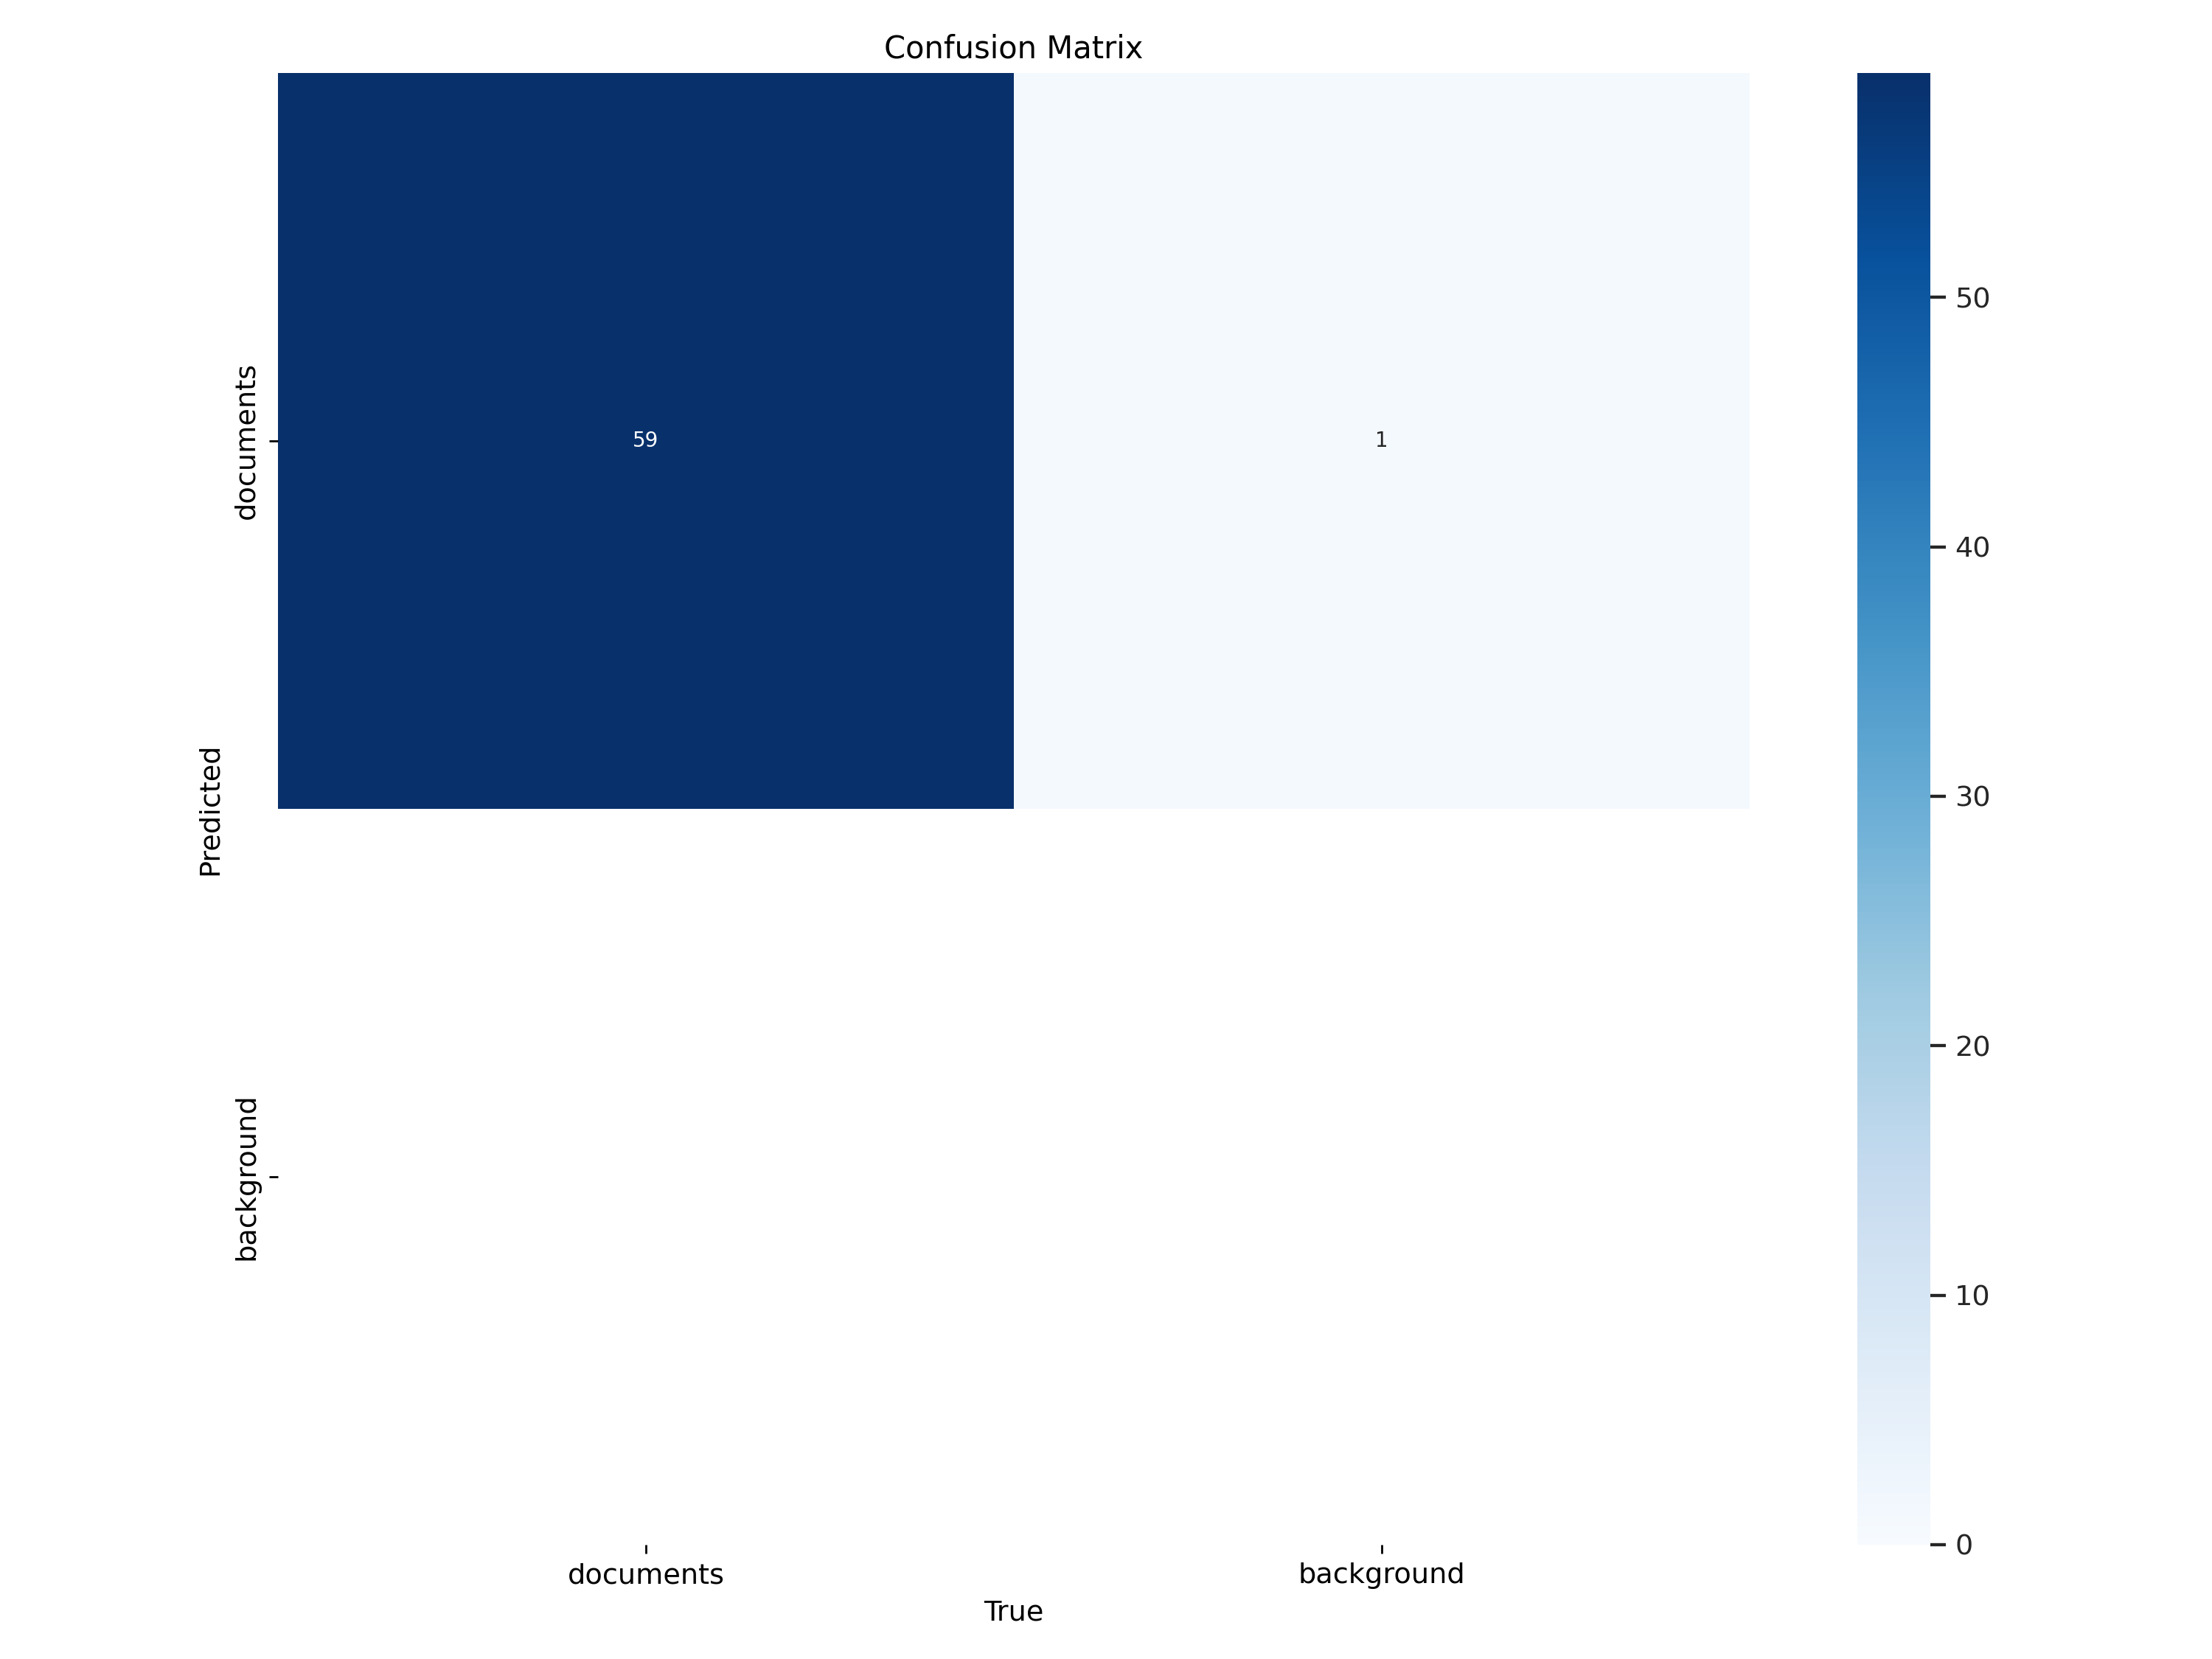

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train/confusion_matrix.png', width=600)

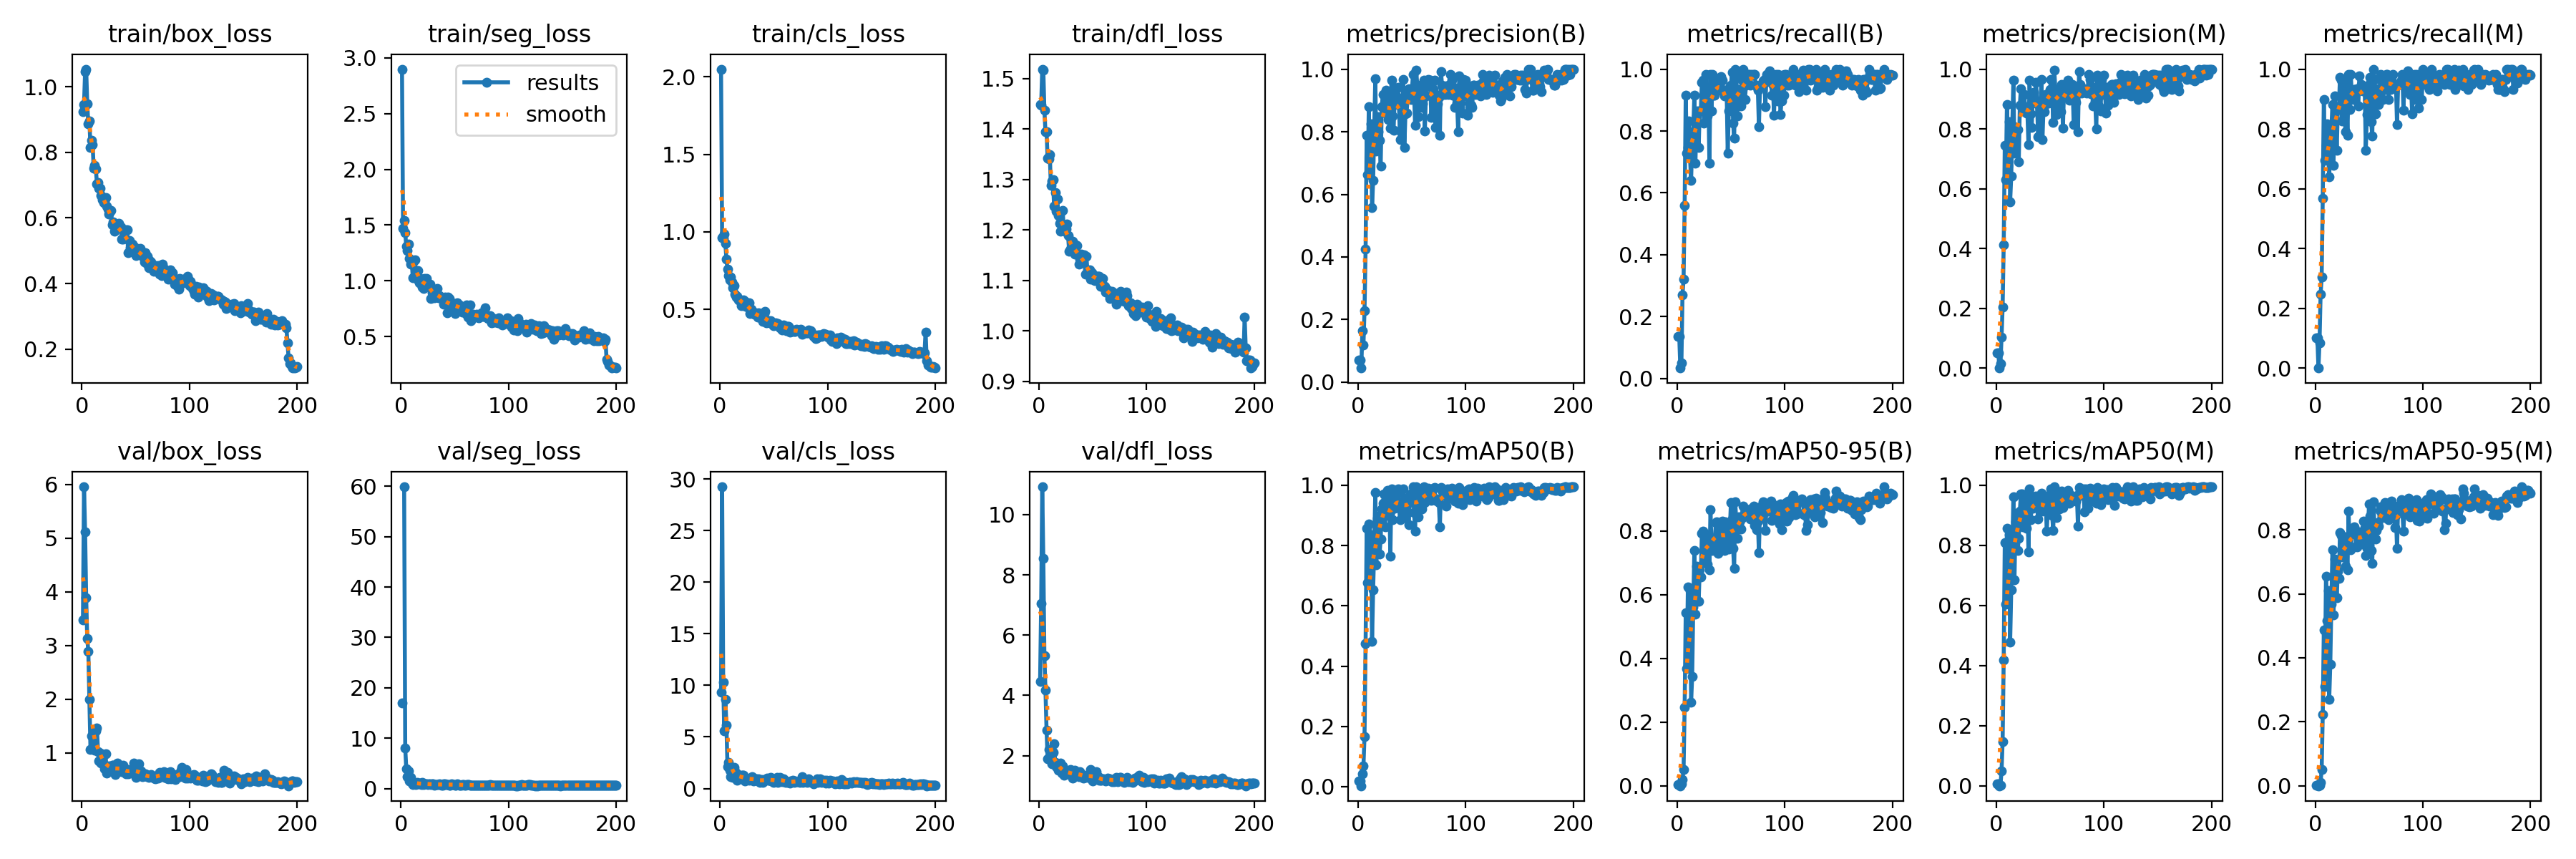

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train/results.png', width=600)

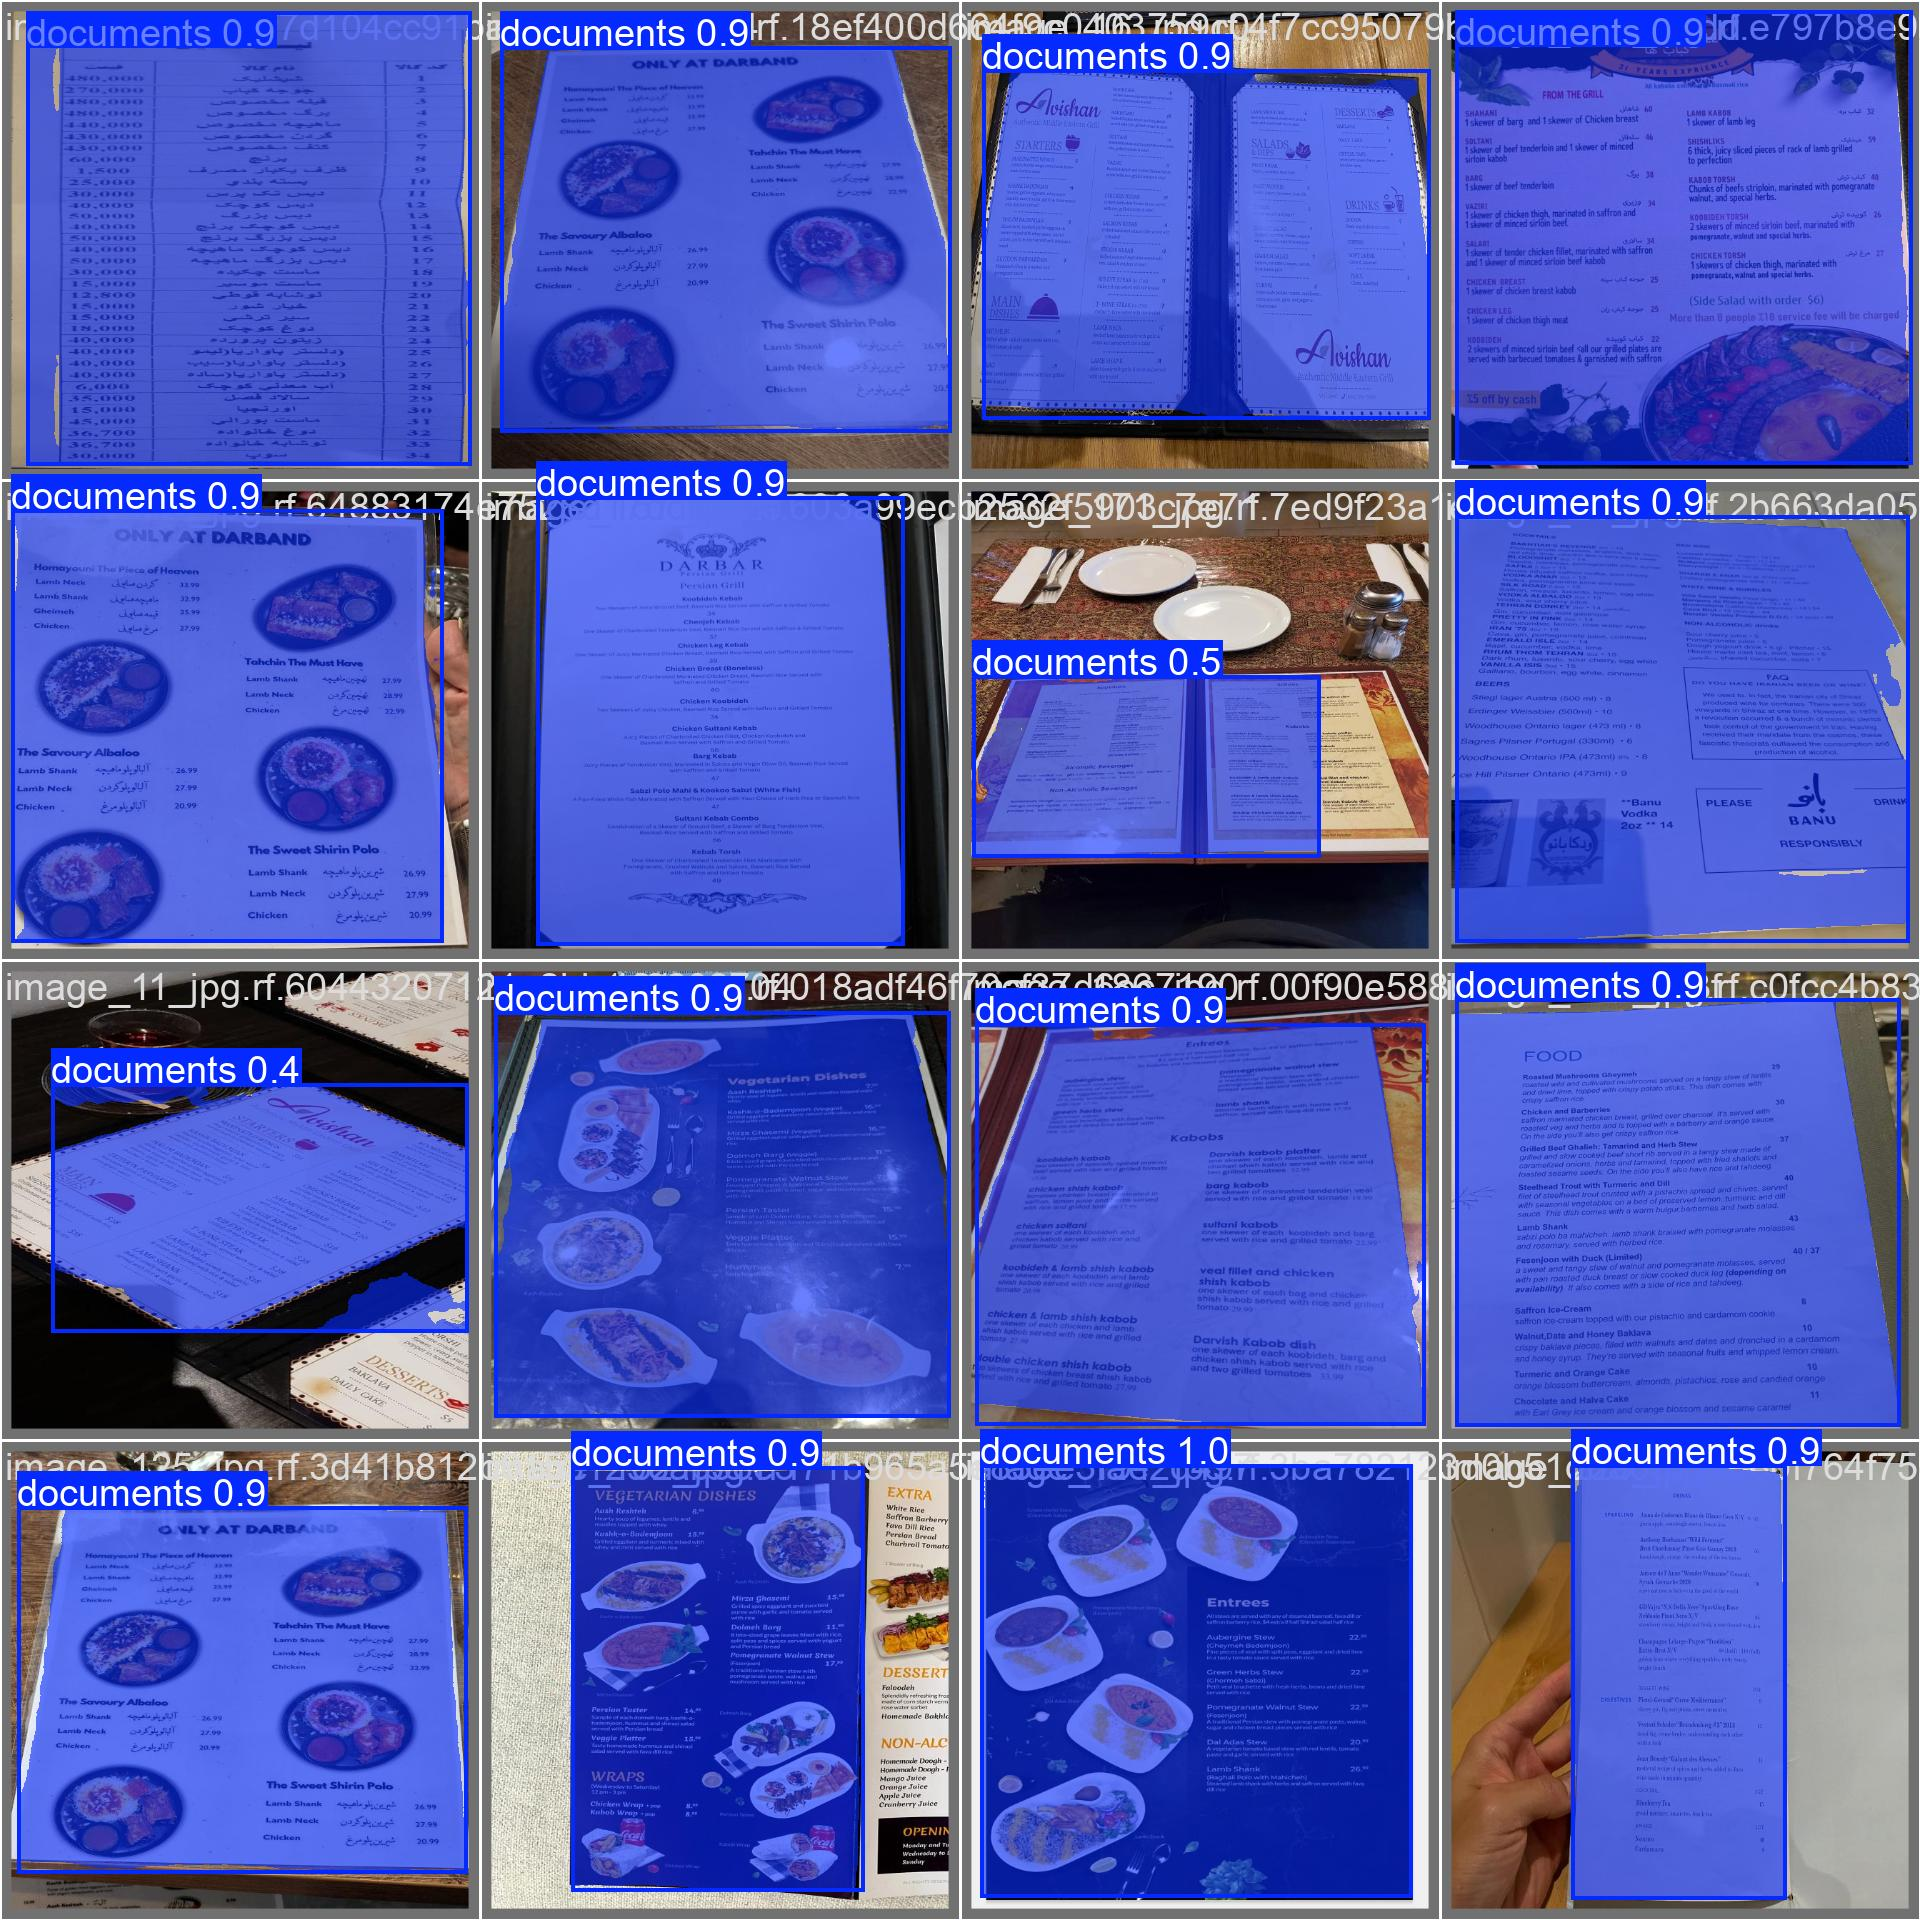

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train/val_batch0_pred.jpg', width=600)

## Validate fine-tuned model

In [ ]:
!yolo task=detect mode=val model={HOME}/runs/segment/train/weights/best.pt data={dataset.location}/data.yaml save_txt=true save_conf=true iou=0.75

WARNING ⚠️ conflicting 'task=detect' passed with 'task=segment' model. Ignoring 'task=detect' and updating to 'task=segment' to match model.
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s-seg summary (fused): 265 layers, 10,067,203 parameters, 0 gradients, 32.8 GFLOPs
val: Scanning /content/datasets/document_detection-9/valid/labels.cache... 59 images, 0 backgrounds, 0 corrupt: 100% 59/59 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% 4/4 [00:07<00:00,  1.87s/it]
                   all         59         59          1          1      0.995      0.936          1          1      0.995      0.935
Speed: 6.1ms preprocess, 15.3ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to runs/segment/val2
💡 Learn more at https://docs.ultralytics.com/modes/val


## Inference with custom model

In [ ]:
!yolo task=detect mode=predict model={HOME}/runs/segment/train/weights/best.pt conf=0.75 source={dataset.location}/test/images save=True save_txt=true save_conf=true iou=0.75

WARNING ⚠️ conflicting 'task=detect' passed with 'task=segment' model. Ignoring 'task=detect' and updating to 'task=segment' to match model.
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s-seg summary (fused): 265 layers, 10,067,203 parameters, 0 gradients, 32.8 GFLOPs

image 1/58 /content/datasets/document_detection-9/test/images/image16_jpg.rf.31a11fbf32592dad7678730b1b9e554d.jpg: 640x640 1 documents, 20.2ms
image 2/58 /content/datasets/document_detection-9/test/images/image17_jpg.rf.11e07ca97336de3e7c4bd4abbcd01c1a.jpg: 640x640 1 documents, 20.3ms
image 3/58 /content/datasets/document_detection-9/test/images/image_104_jpg.rf.8889b0ec6fd69207ddff1772bfb291a8.jpg: 640x640 1 documents, 20.2ms
image 4/58 /content/datasets/document_detection-9/test/images/image_108_jpg.rf.6dda7c5f97b29ac51a4fd3a79bb6d44e.jpg: 640x640 1 documents, 20.2ms
image 5/58 /content/datasets/document_detection-9/test/images/image_118_jpg.rf.c68c9401810af07ac5431070c81b69f0

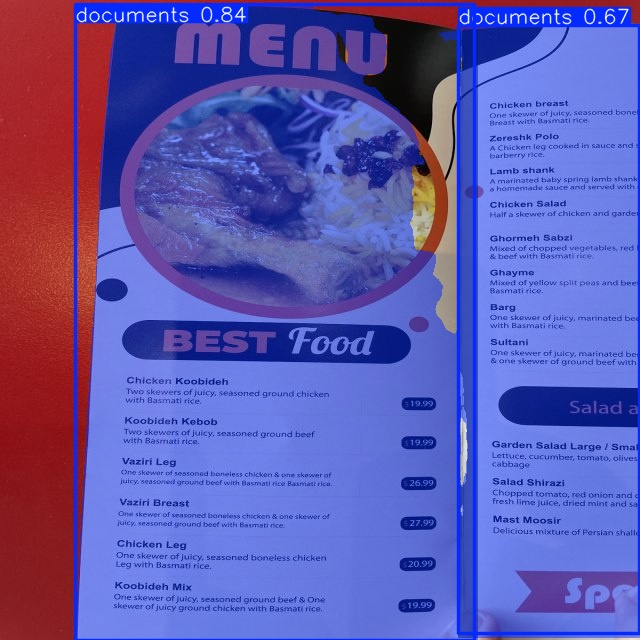

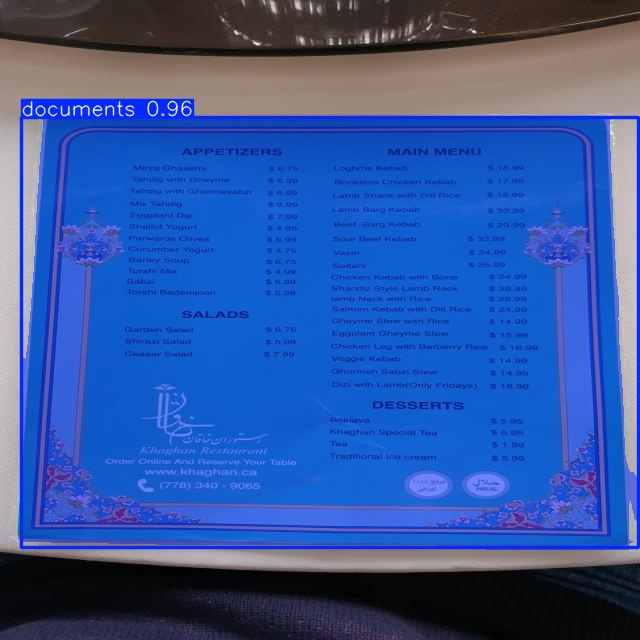

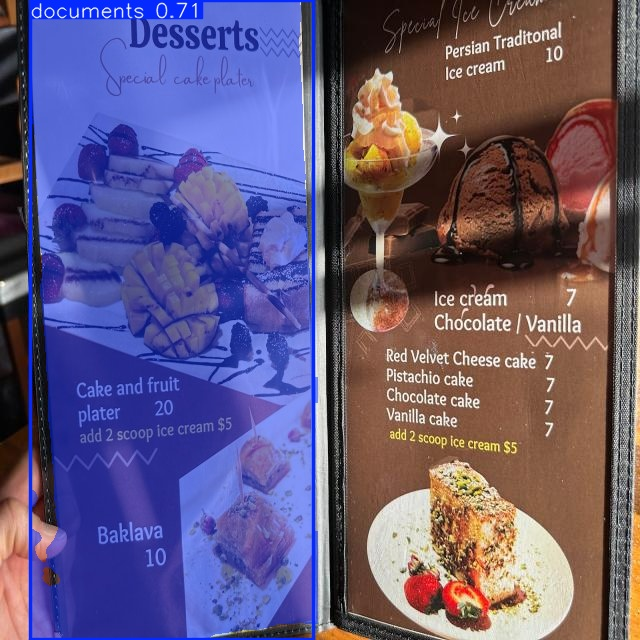

In [ ]:
import glob
import os
from IPython.display import Image as IPyImage, display

latest_folder = max(glob.glob(f'{HOME}/runs/segment/predict*/'), key=os.path.getmtime)
for img in glob.glob(f'{latest_folder}/*.jpg')[:3]:
    display(IPyImage(filename=img, width=600))
    print("\n")

In [ ]:
!ls runs/segment/predict2

ls: cannot access 'runs/segment/predict2': No such file or directory


/content/runs/segment/predict/image_371_jpg.rf.a890d72c7787794e9fd5995131f04de3.jpg


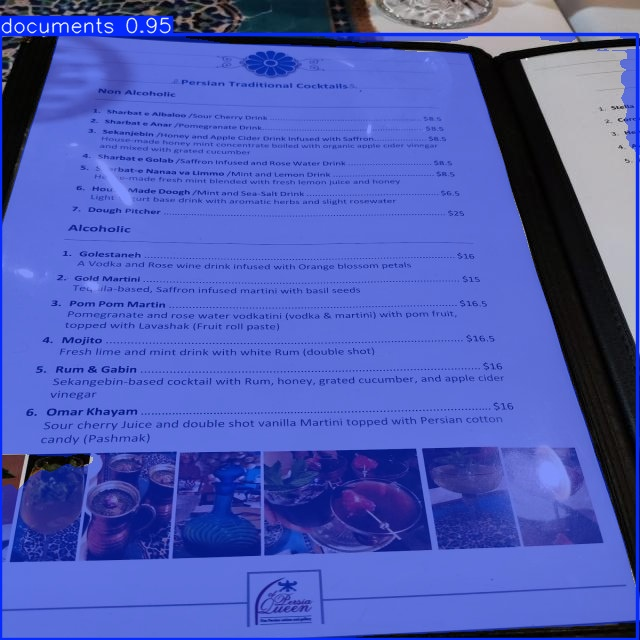

In [ ]:
import glob
import os
from IPython.display import Image as IPyImage, display

latest_folder = max(glob.glob(f'{HOME}/runs/segment/predict/'), key=os.path.getmtime)
for img in glob.glob(f'{latest_folder}/*.jpg')[17:18]:
    print(img)
    display(IPyImage(filename=img, width=600))
    print("\n")

In [ ]:
!zip -r runs.zip runs

  adding: runs/ (stored 0%)
  adding: runs/segment/ (stored 0%)
  adding: runs/segment/predict/ (stored 0%)
  adding: runs/segment/predict/image_352_jpg.rf.007bd660b852d13912fc538fe5e72305.jpg (deflated 3%)
  adding: runs/segment/predict/image_52_jpg.rf.d5b43117c11589339baa4f703cd1dfee.jpg (deflated 3%)
  adding: runs/segment/predict/image_227_jpg.rf.de0b67e61aa4b28ffdcff5df8733a37d.jpg (deflated 3%)
  adding: runs/segment/predict/image_296_jpg.rf.ef97bd98f42ee717a6a606dd9839019f.jpg (deflated 4%)
  adding: runs/segment/predict/image_86_jpg.rf.0b0e00e4462c0dc775728987a409ece1.jpg (deflated 2%)
  adding: runs/segment/predict/image_141_jpg.rf.91cc272bcd5813d1ac942e52065f617c.jpg (deflated 3%)
  adding: runs/segment/predict/image_66_jpg.rf.a3c326f7a28a6322cbe353cef5e704d2.jpg (deflated 3%)
  adding: runs/segment/predict/image_314_jpg.rf.7071423367f14c68845c42ce522ed1b1.jpg (deflated 2%)
  adding: runs/segment/predict/image_139_jpg.rf.7d02ae59a80a09c5c227bcd46c2de4c6.jpg (deflated 4%)
  ad